# Real-data validation: ADMM3D ToMoBAR on K11 dataset 2

Reconstruct `k11_dataset2.npz` and compare numerical checks with the saved slice,
region of interest and line profile.

## Data and execution

Use `k11_dataset2.npz` from [Zenodo record 17252190](https://zenodo.org/records/17252190).
The repository downloader verifies the archive checksums.
Run from the repository root:

```bash
python .scripts/download_zenodo.py Zenodo
python -m pip install -e '.[validation]'
python -m pytest --nbmake --nbmake-timeout=1800 --overwrite docs/source/validation/reconstruction/regularised/admm3d_k11_dataset2.ipynb
```

Use an NVIDIA GPU with compatible CuPy and ToMoBAR installed, plus ASTRA for
ASTRA-based reconstruction. Run notebooks serially. Set `HTTOMOLIBGPU_DATA_DIR`
to use an archive stored elsewhere.

Documentation builds render saved outputs without running GPU computations.
Execute with `--overwrite` before building documentation to update the results.


In [1]:
import gc
import hashlib
import json
import math
import os
import platform
import time
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

import cupy as cp
import httomolibgpu
import matplotlib.pyplot as plt
import numpy as np
import tomobar

from httomolibgpu.prep.normalize import dark_flat_field_correction, minus_log
from httomolibgpu.recon.algorithm import ADMM3d_tomobar

repo_root = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "pyproject.toml").is_file() and (p / "httomolibgpu").is_dir()
    ),
    None,
)
data_dir = os.environ.get("HTTOMOLIBGPU_DATA_DIR")
if data_dir is None:
    if repo_root is None:
        raise FileNotFoundError(
            "Set HTTOMOLIBGPU_DATA_DIR to the Zenodo archive directory"
        )
    data_dir = repo_root / "Zenodo"
data_path = Path(data_dir).expanduser() / "k11_dataset2.npz"
if not data_path.is_file():
    raise FileNotFoundError(
        f"Missing {data_path}; run .scripts/download_zenodo.py first"
    )

checksum = hashlib.sha256()
with data_path.open("rb") as stream:
    for chunk in iter(lambda: stream.read(1024 * 1024), b""):
        checksum.update(chunk)


def package_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed as a distribution"


# Make the linearised solver's random power-method initialisation repeatable.
seed = 0
cp.random.seed(seed)
props = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)
provenance = {
    "dataset": data_path.name,
    "zenodo_record": "17252190",
    "sha256": checksum.hexdigest(),
    "python": platform.python_version(),
    "packages": {
        name: package_version(name)
        for name in ("httomolibgpu", "tomobar", "astra-toolbox", "numpy")
    },
    "source_paths": {
        "httomolibgpu": httomolibgpu.__file__,
        "tomobar": tomobar.__file__,
    },
    "cupy": cp.__version__,
    "cuda_runtime": cp.cuda.runtime.runtimeGetVersion(),
    "cuda_driver": cp.cuda.runtime.driverGetVersion(),
    "gpu": (
        props["name"].decode() if isinstance(props["name"], bytes) else props["name"]
    ),
    "cupy_random_seed": seed,
}
print(json.dumps(provenance, indent=2))

{
  "dataset": "k11_dataset2.npz",
  "zenodo_record": "17252190",
  "sha256": "661aded97455d9c5623226098676eaed60999ce70be5e1dbbee9cc2eedd35f7c",
  "python": "3.14.7",
  "packages": {
    "httomolibgpu": "6.0.1.post16+git.bbaa03d2.dirty",
    "tomobar": "2026.3.1.0",
    "astra-toolbox": "2.5.0",
    "numpy": "2.4.6"
  },
  "source_paths": {
    "httomolibgpu": "/home/algol/Documents/DEV/httomolibgpu/httomolibgpu/__init__.py",
    "tomobar": "/home/algol/Documents/DEV/ToMoBAR/tomobar/__init__.py"
  },
  "cupy": "14.2.0",
  "cuda_runtime": 13020,
  "cuda_driver": 13020,
  "gpu": "NVIDIA GeForce RTX 4060",
  "cupy_random_seed": 0
}


## Preprocessing

Input axes are `(angle, detector row, detector column)`.
Apply dark/flat correction and `minus_log` to the full acquisition, then select
detector rows `5:8`. Use all 500 angles in radians and centre 1280.25 pixels.


Reconstruction input: (500, 3, 2560)


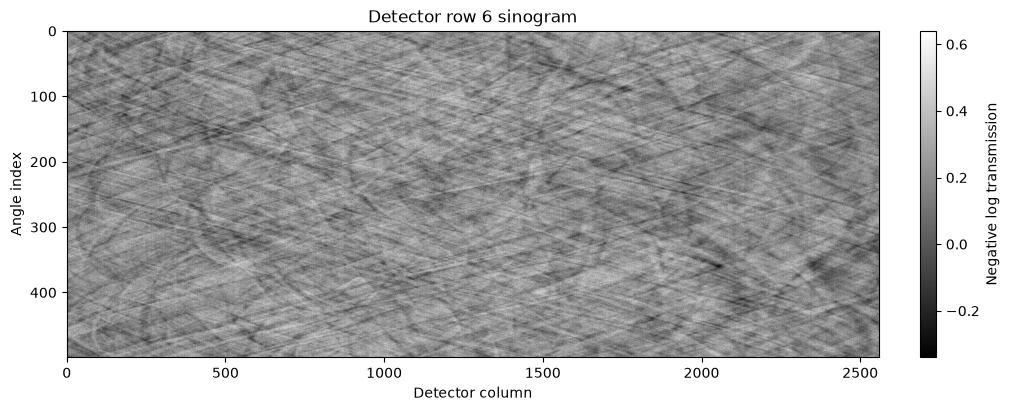

In [2]:
with np.load(data_path, allow_pickle=False) as archive:
    projdata = cp.asarray(archive["projdata"])
    flats = cp.asarray(archive["flats"])
    darks = cp.asarray(archive["darks"])
    angles = archive["angles"].copy()

data_normalised = dark_flat_field_correction(projdata, flats, darks)
data_normalised = minus_log(data_normalised)
del projdata, flats, darks
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
reconstruction_input = cp.ascontiguousarray(data_normalised[:, 5:8, :])
del data_normalised
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
recon_angles = np.deg2rad(angles)
assert reconstruction_input.shape == (500, 3, 2560)
assert len(recon_angles) == reconstruction_input.shape[0]
assert reconstruction_input.dtype == cp.float32
assert bool(cp.isfinite(reconstruction_input).all())
print("Reconstruction input:", reconstruction_input.shape)

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
im = ax.imshow(reconstruction_input[:, 1, :].get(), cmap="gray", aspect="auto")
ax.set(title="Detector row 6 sinogram", xlabel="Detector column", ylabel="Angle index")
fig.colorbar(im, ax=ax, label="Negative log transmission")
plt.show()
plt.close(fig)

## Reconstruction and regression assertions

Use 10 full-data ADMM iterations with `cg` data solves,
zero initialisation and PD-TV strength `0.01`.
Automatic detector padding with `initialisation=None` retains the unpadded
output width: `(2560, 3, 2560)`. The shape check follows the selected parameters.
Output axes are `(Y, detector row, X)`. Numerical assertions run after plotting.


In [3]:
parameters = {
    "center": 1280.25,
    "detector_pad": True,
    "recon_size": None,
    "recon_mask_radius": 2.0,
    "iterations": 10,
    "data_fidelity": "LS",
    "initialisation": None,
    "rho": 1.0,
    "relaxation": 1.7,
    "data_solver": "cg",
    "lipschitz_constant": None,
    "regularisation_type": "PD_TV",
    "regularisation_parameter": 0.01,
    "regularisation_iterations": 40,
    "regularisation_half_precision": True,
    "nonnegativity": False,
    "gpu_id": 0,
}
print("Reconstruction parameters:", json.dumps(parameters, indent=2))
cp.cuda.get_current_stream().synchronize()
start = time.perf_counter()
recon_gpu = ADMM3d_tomobar(reconstruction_input, recon_angles, **parameters)
cp.cuda.get_current_stream().synchronize()
elapsed_seconds = time.perf_counter() - start

assert isinstance(recon_gpu, cp.ndarray)
assert recon_gpu.flags.c_contiguous
assert recon_gpu.dtype == cp.float32
# Match the wrapper's output-size policy for the selected initialisation.
detector_width = reconstruction_input.shape[2]
padding = parameters["detector_pad"]
if padding is True:
    half_width = detector_width // 2
    extra = int(np.sqrt(2 * half_width**2)) - half_width
    padding = extra + extra // 2
elif padding is False:
    padding = 0
expected_width = parameters["recon_size"] or detector_width
if parameters["initialisation"] is not None and padding > 0:
    expected_width = detector_width + 2 * padding
expected_shape = (expected_width, reconstruction_input.shape[1], expected_width)
assert recon_gpu.shape == expected_shape, (
    f"Unexpected reconstruction shape: {recon_gpu.shape}; expected {expected_shape} "
    f"for initialisation={parameters['initialisation']!r}, detector_pad="
    f"{parameters['detector_pad']!r}, recon_size={parameters['recon_size']!r}"
)
assert bool(cp.isfinite(recon_gpu).all()), "Non-finite reconstruction"
recon_data = cp.asnumpy(recon_gpu)
del recon_gpu, reconstruction_input
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
print(f"Reconstruction completed in {elapsed_seconds:.3f} seconds")

Reconstruction parameters: {
  "center": 1280.25,
  "detector_pad": true,
  "recon_size": null,
  "recon_mask_radius": 2.0,
  "iterations": 10,
  "data_fidelity": "LS",
  "initialisation": null,
  "rho": 1.0,
  "relaxation": 1.7,
  "data_solver": "cg",
  "lipschitz_constant": null,
  "regularisation_type": "PD_TV",
  "regularisation_parameter": 0.01,
  "regularisation_iterations": 40,
  "regularisation_half_precision": true,
  "nonnegativity": false,
  "gpu_id": 0
}


Reconstruction completed in 20.006 seconds


In [4]:
reference_sum = 1626.1884765625
absolute_tolerance = 1e-3
observed_sum = float(np.sum(recon_data, dtype=np.float32))
sum_matches = math.isclose(observed_sum, reference_sum, abs_tol=absolute_tolerance)
metrics = {
    "shape": list(recon_data.shape),
    "dtype": str(recon_data.dtype),
    "c_contiguous": recon_data.flags.c_contiguous,
    "sum_float32": observed_sum,
    "reference_sum": reference_sum,
    "absolute_sum_difference": abs(observed_sum - reference_sum),
    "absolute_tolerance": absolute_tolerance,
    "relative_tolerance": 1e-9,
    "sum_check_passed": sum_matches,
    "mean_float64": float(recon_data.mean(dtype=np.float64)),
    "minimum": float(recon_data.min()),
    "maximum": float(recon_data.max()),
    "reconstruction_seconds": elapsed_seconds,
}
print(json.dumps(metrics, indent=2))

{
  "shape": [
    2560,
    3,
    2560
  ],
  "dtype": "float32",
  "c_contiguous": true,
  "sum_float32": 1626.1884765625,
  "reference_sum": 1626.1884765625,
  "absolute_sum_difference": 0.0,
  "absolute_tolerance": 0.001,
  "relative_tolerance": 1e-09,
  "sum_check_passed": true,
  "mean_float64": 8.271222476906571e-05,
  "minimum": -0.0020554265938699245,
  "maximum": 0.005702907219529152,
  "reconstruction_seconds": 20.006169466999836
}


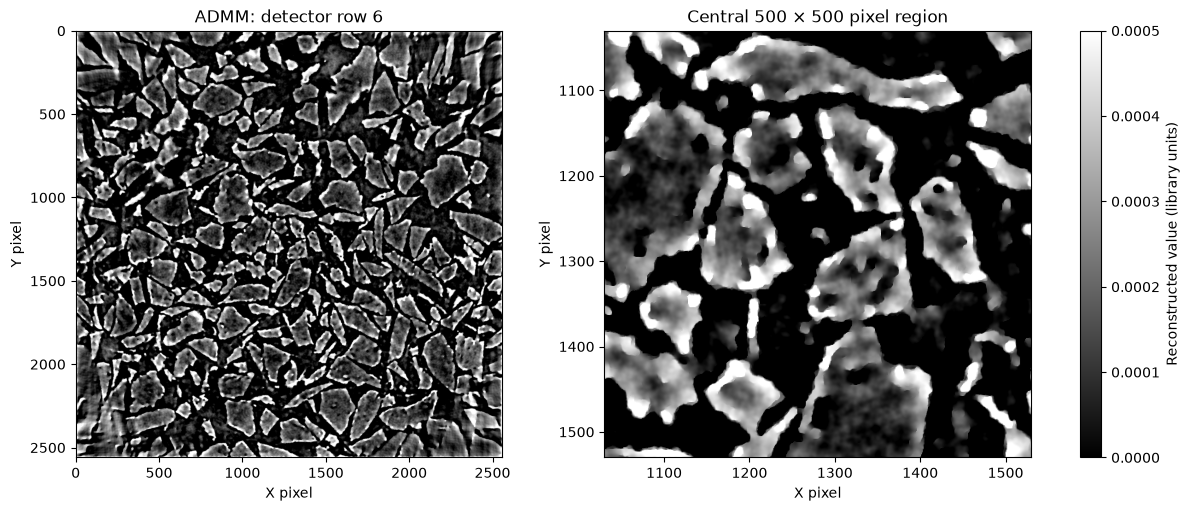

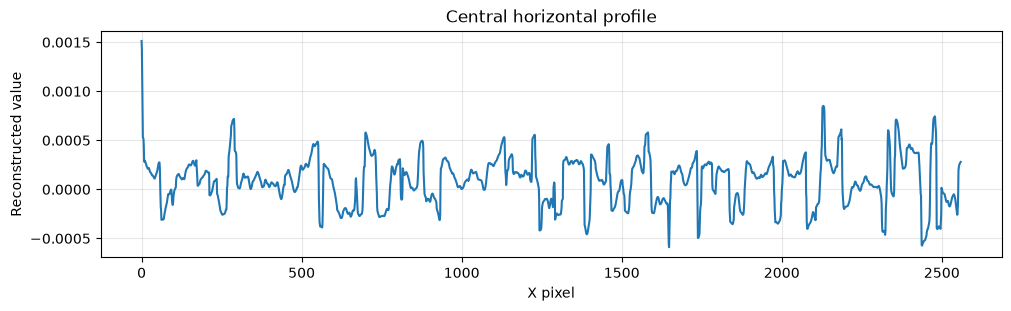

In [5]:
image = recon_data[:, 1, :]
cy, cx = (size // 2 for size in image.shape)
half_width = 250
roi = image[cy - half_width : cy + half_width, cx - half_width : cx + half_width]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
limits = {"vmin": 0, "vmax": 0.0005, "cmap": "gray"}
im = axes[0].imshow(image, **limits)
axes[0].set(title="ADMM: detector row 6", xlabel="X pixel", ylabel="Y pixel")
axes[1].imshow(
    roi,
    extent=(cx - half_width, cx + half_width, cy + half_width, cy - half_width),
    **limits,
)
axes[1].set(title="Central 500 × 500 pixel region", xlabel="X pixel", ylabel="Y pixel")
fig.colorbar(im, ax=axes, label="Reconstructed value (library units)")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 3), constrained_layout=True)
ax.plot(image[cy, :])
ax.set(
    title="Central horizontal profile", xlabel="X pixel", ylabel="Reconstructed value"
)
ax.grid(alpha=0.3)
plt.show()
plt.close(fig)

In [6]:
assert sum_matches, (
    f"Reconstruction sum changed: {observed_sum} (expected {reference_sum}; "
    f"absolute difference {abs(observed_sum-reference_sum)}, tolerance {absolute_tolerance})"
)
print("All structural and numerical regression checks passed.")

del recon_data, image, roi
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
cp.get_default_pinned_memory_pool().free_all_blocks()

All structural and numerical regression checks passed.
